# Fashion-MNIST – Random Forest Classification

## Objective

The objective of this notebook is to investigate the
predictive performance and computational efficiency of
a Random Forest classifier on the Fashion-MNIST dataset.

The experiments follow the shared dataset split,
preprocessing pipeline and evaluation protocol.

The analysis focuses on:

- Baseline model development and evaluation
- Hyperparameter optimization
- Alternative feature representations (PCA and HOG)
- Computational efficiency and model complexity
- Validation-based model selection
- Final test set evaluation
- Pixel-level feature importance analysis

## 1. Setup and Configuration

In [1]:
import sys
from pathlib import Path
from time import perf_counter

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
)

PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

In [2]:
from src.models.random_forest import (
    BASELINE_PARAMS,
    build_random_forest,
)
from src.preprocessing.dataset import load_dataset
from src.preprocessing.ml import build_ml_datasets
from src.preprocessing.split import load_split

RANDOM_SEED = 42

np.random.seed(RANDOM_SEED)

FIGURES_DIR = PROJECT_ROOT / "results" / "figures" / "random_forest"
EXPERIMENTS_DIR = PROJECT_ROOT / "results" / "experiments"
ARTIFACTS_DIR = PROJECT_ROOT / "artifacts" / "ml"

for directory in [FIGURES_DIR, EXPERIMENTS_DIR, ARTIFACTS_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

PROJECT_PALETTE = [
    "#DFE9EF",
    "#BDCEDB",
    "#8FA7BD",
    "#5E7891",
    "#32485F",
    "#1E3247",
    "#0F1B2A",
]

PRIMARY_COLOR = "#5E7891"
SECONDARY_COLOR = "#32485F"
ACCENT_COLOR = "#8FA7BD"

sns.set_theme(
    style="whitegrid",
    palette=PROJECT_PALETTE,
)

plt.rcParams.update(
    {
        "figure.dpi": 120,
        "savefig.dpi": 300,
        "axes.titlesize": 13,
        "axes.labelsize": 11,
    }
)

print(f"Project root: {PROJECT_ROOT}")
print(f"Python version: {sys.version.split()[0]}")
print(f"Random seed: {RANDOM_SEED}")

Project root: c:\Users\SUB\OneDrive - Horváth & Partner GmbH\Asztal\Github\DLProject_FashionMNIST
Python version: 3.12.10
Random seed: 42


## 2. Dataset Loading and Preprocessing

The dataset is loaded using the shared data loading module
and the predefined stratified training-validation split.

The baseline preprocessing configuration consists of
pixel scaling to the [0, 1] range and flattening each
28 × 28 image into a 784-dimensional feature vector.

No standardization, dimensionality reduction or additional
feature extraction is applied to the baseline model.

In [3]:
train_dataset, test_dataset = load_dataset()

train_indices, val_indices = load_split()

class_names = train_dataset.classes

print(f"Original training samples: {len(train_dataset):,}")
print(f"Training samples: {len(train_indices):,}")
print(f"Validation samples: {len(val_indices):,}")
print(f"Test samples: {len(test_dataset):,}")
print(f"Number of classes: {len(class_names)}")

Original training samples: 60,000
Training samples: 50,000
Validation samples: 10,000
Test samples: 10,000
Number of classes: 10


In [4]:
BASELINE_PREPROCESSING = {
    "standardize": False,
    "pca_components": None,
    "use_hog": False,
    "seed": RANDOM_SEED,
}

preprocessing_start = perf_counter()

datasets, preprocessor = build_ml_datasets(
    train_dataset,
    test_dataset,
    train_indices,
    val_indices,
    **BASELINE_PREPROCESSING,
)

baseline_preprocessing_time = perf_counter() - preprocessing_start

X_train, y_train = datasets["train"]
X_val, y_val = datasets["val"]
X_test, y_test = datasets["test"]

print(f"Preprocessing time: {baseline_preprocessing_time:.2f} seconds")

Preprocessing time: 1.38 seconds


In [5]:
dataset_summary = pd.DataFrame(
    [
        {
            "Dataset": name,
            "Samples": X.shape[0],
            "Features": X.shape[1],
            "Feature dtype": str(X.dtype),
            "Label dtype": str(y.dtype),
        }
        for name, (X, y) in datasets.items()
    ]
)

display(dataset_summary)

assert X_train.shape == (50_000, 784)
assert X_val.shape == (10_000, 784)
assert X_test.shape == (10_000, 784)

assert np.array_equal(
    np.bincount(y_train),
    np.full(10, 5_000),
)

assert np.array_equal(
    np.bincount(y_val),
    np.full(10, 1_000),
)

print("All dataset validation checks passed.")

,Dataset,Samples,Features,Feature dtype,Label dtype
0,train,50000,784,float32,int64
1,val,10000,784,float32,int64
2,test,10000,784,float32,int64


All dataset validation checks passed.


## 3. Random Forest Baseline

The baseline Random Forest classifier consists of
100 decision trees trained on the original scaled
pixel features.

The model uses the default scikit-learn hyperparameters,
a fixed random seed and parallel processing.

The baseline results serve as a reference for subsequent
hyperparameter and preprocessing experiments.

In [6]:
baseline_model = build_random_forest()

display(
    pd.DataFrame(
        BASELINE_PARAMS.items(),
        columns=["Parameter", "Value"],
    )
)

,Parameter,Value
0,n_estimators,100
1,criterion,gini
2,max_depth,None
3,min_samples_split,2
4,min_samples_leaf,1
5,max_features,sqrt
6,bootstrap,True
7,class_weight,None
8,random_state,42
9,n_jobs,-1


In [7]:
print("Training Random Forest baseline...")

training_start = perf_counter()

baseline_model.fit(X_train, y_train)

baseline_training_time = perf_counter() - training_start

print("Baseline training completed.")
print(f"Training time: {baseline_training_time:.2f} seconds")

Training Random Forest baseline...
Baseline training completed.
Training time: 9.25 seconds


In [8]:
y_train_pred = baseline_model.predict(X_train)

inference_start = perf_counter()

y_val_pred = baseline_model.predict(X_val)

baseline_inference_time = perf_counter() - inference_start

baseline_results = pd.DataFrame(
    {
        "Metric": ["Accuracy", "Macro F1-score"],
        "Training": [
            accuracy_score(y_train, y_train_pred),
            f1_score(y_train, y_train_pred, average="macro"),
        ],
        "Validation": [
            accuracy_score(y_val, y_val_pred),
            f1_score(y_val, y_val_pred, average="macro"),
        ],
    }
)

display(baseline_results.round(4))

print(f"Training time: {baseline_training_time:.2f} seconds")
print(f"Validation inference time: {baseline_inference_time:.4f} seconds")

,Metric,Training,Validation
0,Accuracy,1.0,0.8836
1,Macro F1-score,1.0,0.8823


Training time: 9.25 seconds
Validation inference time: 0.1009 seconds


### 3.1. Class-Level Performance

The confusion matrix and classification report are used
to investigate class-specific prediction performance
and identify the most frequently confused categories.

The results can be compared with the inter-class
cosine similarity analysis performed during EDA.

In [9]:
baseline_class_report = pd.DataFrame(
    classification_report(
        y_val,
        y_val_pred,
        labels=np.arange(len(class_names)),
        target_names=class_names,
        output_dict=True,
        zero_division=0,
    )
).T

display(baseline_class_report.round(4))

,precision,recall,f1-score,support
T-shirt/top,0.8325,0.8800,0.8556,1000.0000
Trouser,0.9939,0.9710,0.9823,1000.0000
Pullover,0.7676,0.8190,0.7925,1000.0000
Dress,0.8956,0.9090,0.9022,1000.0000
Coat,0.7651,0.8210,0.7921,1000.0000
Sandal,0.9657,0.9580,0.9618,1000.0000
Shirt,0.7569,0.6070,0.6737,1000.0000
Sneaker,0.9446,0.9380,0.9413,1000.0000
Bag,0.9653,0.9750,0.9701,1000.0000
Ankle boot,0.9448,0.9580,0.9513,1000.0000


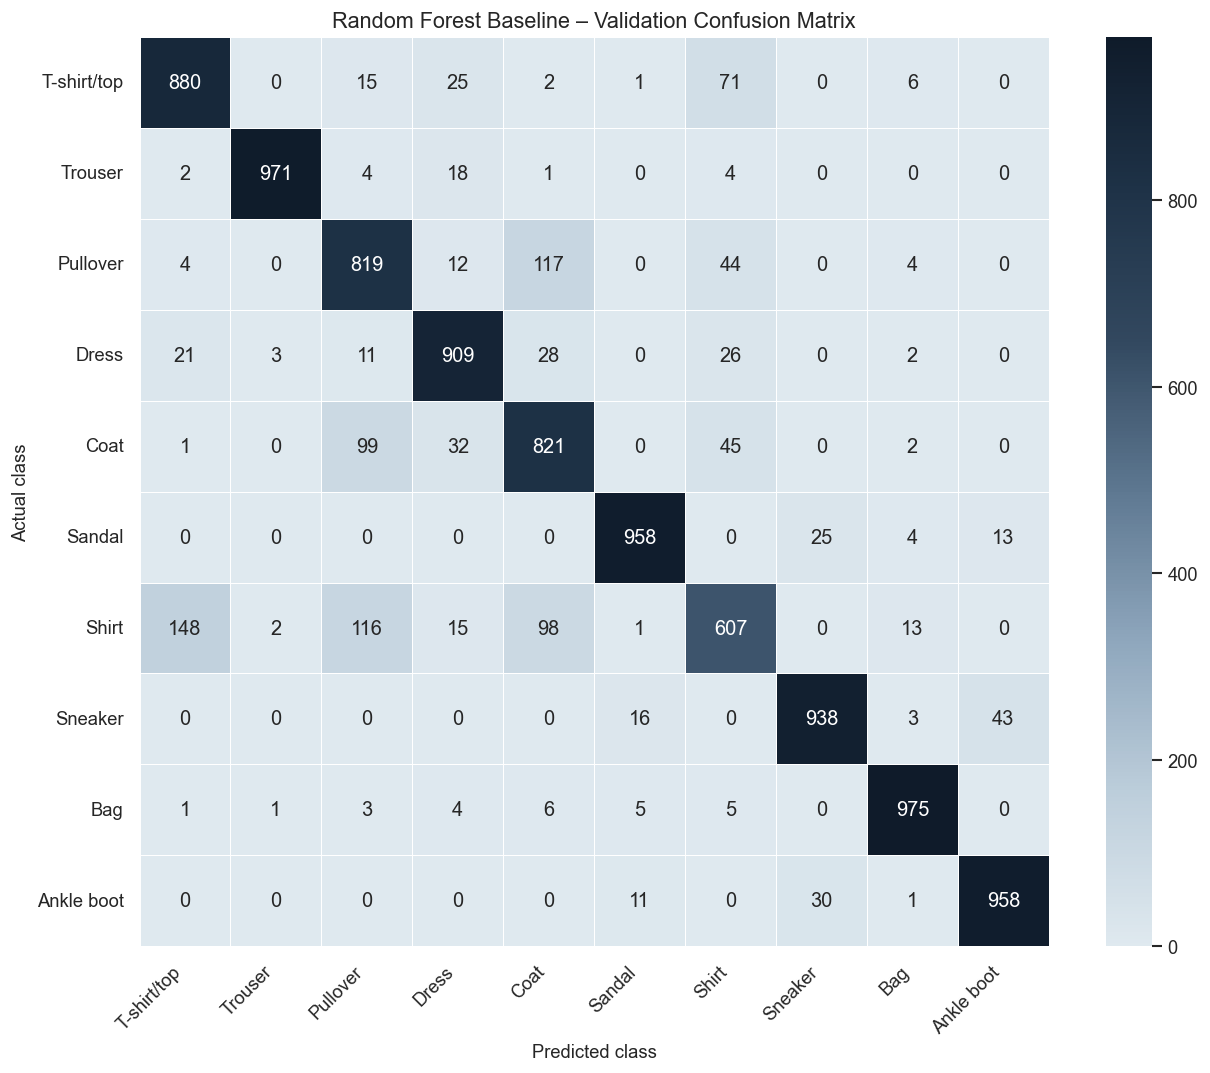

In [10]:
from matplotlib.colors import LinearSegmentedColormap

project_cmap = LinearSegmentedColormap.from_list(
    "project_palette",
    PROJECT_PALETTE,
)

baseline_cm = confusion_matrix(
    y_val,
    y_val_pred,
    labels=np.arange(len(class_names)),
)

fig, ax = plt.subplots(figsize=(11, 9))

sns.heatmap(
    baseline_cm,
    annot=True,
    fmt="d",
    cmap=project_cmap,
    xticklabels=class_names,
    yticklabels=class_names,
    square=True,
    linewidths=0.5,
    ax=ax,
)

ax.set_title("Random Forest Baseline – Validation Confusion Matrix")
ax.set_xlabel("Predicted class")
ax.set_ylabel("Actual class")

plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

fig.tight_layout()

fig.savefig(
    FIGURES_DIR / "baseline_confusion_matrix.png",
    bbox_inches="tight",
)

plt.show()

### 3.2. Pixel-Level Feature Importance

The impurity-based feature importance scores of the
trained Random Forest classifier are reshaped into
the original 28 × 28 image dimensions.

The resulting heatmap illustrates which pixel
positions contribute most strongly to the decision
tree splits across the ensemble.

Feature importance scores represent global model
behavior rather than explanations of individual
predictions.

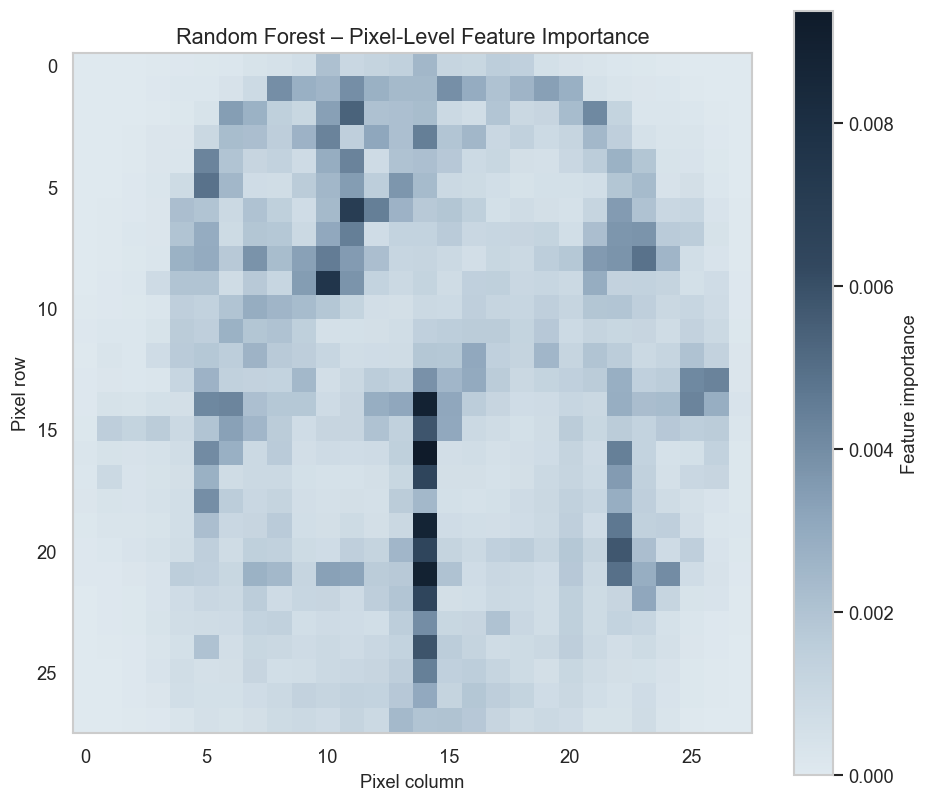

In [11]:
pixel_importance = baseline_model.feature_importances_.reshape(28, 28)

fig, ax = plt.subplots(figsize=(8, 7))

image = ax.imshow(
    pixel_importance,
    cmap=project_cmap,
    interpolation="nearest",
)

ax.set_title("Random Forest – Pixel-Level Feature Importance")
ax.set_xlabel("Pixel column")
ax.set_ylabel("Pixel row")
ax.grid(False)

fig.colorbar(
    image,
    ax=ax,
    label="Feature importance",
)

fig.tight_layout()

fig.savefig(
    FIGURES_DIR / "baseline_feature_importance.png",
    bbox_inches="tight",
)

plt.show()

### 3.3. Baseline Key Findings

The baseline Random Forest achieved a validation
accuracy of 88.36% and a macro F1-score of 88.23%,
with a training time of 9.25 seconds.

The perfect training accuracy and the 11.64 percentage
point generalization gap indicate substantial overfitting.

The Shirt category presents the greatest classification
difficulty, with a recall of only 60.7%.

Four highly similar upper-body clothing category pairs
account for 63.4% of all validation misclassifications.
This observation is consistent with the cosine similarity
analysis performed during EDA.

The feature importance heatmap indicates that central
pixel positions and certain contour-related regions
contribute strongly to the model's decision-making.

These findings motivate further experiments involving
tree regularization, ensemble size and alternative
feature representations.

## 4. Hyperparameter Optimization

Controlled experiments are performed to investigate
the impact of individual Random Forest hyperparameters.

Each experiment uses the same training-validation split,
baseline feature representation and random seed.

Only one hyperparameter is modified at a time to isolate
its effect on predictive performance, generalization
and computational efficiency.

Model selection is based exclusively on validation results.

In [12]:
import json
from tempfile import TemporaryDirectory


def evaluate_experiment(
    run_id,
    description,
    model,
    datasets,
    training_time,
    preprocessing_time,
    preprocessing_params,
):
    X_train_exp, y_train_exp = datasets["train"]
    X_val_exp, y_val_exp = datasets["val"]

    # Training predictions
    y_train_pred_exp = model.predict(X_train_exp)

    # Inference warm-up
    model.predict(X_val_exp)

    # Repeated validation inference measurements
    inference_times = []

    for _ in range(5):
        start = perf_counter()
        y_val_pred_exp = model.predict(X_val_exp)
        inference_times.append(perf_counter() - start)

    inference_time = float(np.median(inference_times))

    # Predictive performance
    train_accuracy = accuracy_score(y_train_exp, y_train_pred_exp)
    val_accuracy = accuracy_score(y_val_exp, y_val_pred_exp)

    train_f1 = f1_score(
        y_train_exp,
        y_train_pred_exp,
        average="macro",
    )
    val_f1 = f1_score(
        y_val_exp,
        y_val_pred_exp,
        average="macro",
    )

    # Serialized model size (uncompressed)
    with TemporaryDirectory() as temp_dir:
        model_path = Path(temp_dir) / "model.joblib"

        joblib.dump(model, model_path, compress=0)

        model_size_mb = model_path.stat().st_size / 1024**2

    return {
        "run_id": run_id,
        "description": description,
        "n_features": X_train_exp.shape[1],
        "train_accuracy": train_accuracy,
        "val_accuracy": val_accuracy,
        "train_macro_f1": train_f1,
        "val_macro_f1": val_f1,
        "accuracy_gap": train_accuracy - val_accuracy,
        "preprocessing_time_s": preprocessing_time,
        "training_time_s": training_time,
        "inference_time_s": inference_time,
        "model_size_mib": model_size_mb,
        "model_params": json.dumps(
            model.get_params(),
            sort_keys=True,
        ),
        "preprocessing_params": json.dumps(
            preprocessing_params,
            sort_keys=True,
        ),
    }

In [13]:
def run_rf_experiment(
    run_id,
    description,
    datasets,
    preprocessing_time,
    preprocessing_params,
    model_overrides=None,
):
    if model_overrides is None:
        model_overrides = {}

    X_train_exp, y_train_exp = datasets["train"]

    model = build_random_forest(**model_overrides)

    print(f"Running {run_id}: {description}")

    start = perf_counter()

    model.fit(X_train_exp, y_train_exp)

    training_time = perf_counter() - start

    result = evaluate_experiment(
        run_id=run_id,
        description=description,
        model=model,
        datasets=datasets,
        training_time=training_time,
        preprocessing_time=preprocessing_time,
        preprocessing_params=preprocessing_params,
    )

    print(
        f"Validation accuracy: {result['val_accuracy']:.4f} | "
        f"Macro F1: {result['val_macro_f1']:.4f} | "
        f"Training time: {training_time:.2f}s"
    )

    return result

In [14]:
experiment_results = []

baseline_result = evaluate_experiment(
    run_id="RF-00",
    description="Baseline",
    model=baseline_model,
    datasets=datasets,
    training_time=baseline_training_time,
    preprocessing_time=baseline_preprocessing_time,
    preprocessing_params=BASELINE_PREPROCESSING,
)

experiment_results.append(baseline_result)

display(pd.DataFrame(experiment_results))

,run_id,description,n_features,train_accuracy,val_accuracy,train_macro_f1,val_macro_f1,accuracy_gap,preprocessing_time_s,training_time_s,inference_time_s,model_size_mib,model_params,preprocessing_params
0,RF-00,Baseline,784,1.0,0.8836,1.0,0.882301,0.1164,1.376308,9.252571,0.085845,116.126382,"{""bootstrap"": true, ""ccp_alpha"": 0.0, ""class_w...","{""pca_components"": null, ""seed"": 42, ""standard..."


In [15]:
hyperparameter_experiments = [
    {
        "run_id": "RF-01",
        "description": "50 trees",
        "model_overrides": {"n_estimators": 50},
    },
    {
        "run_id": "RF-02",
        "description": "200 trees",
        "model_overrides": {"n_estimators": 200},
    },
    {
        "run_id": "RF-03",
        "description": "Maximum depth 20",
        "model_overrides": {"max_depth": 20},
    },
    {
        "run_id": "RF-04",
        "description": "Minimum leaf size 3",
        "model_overrides": {"min_samples_leaf": 3},
    },
    {
        "run_id": "RF-05",
        "description": "Log2 feature sampling",
        "model_overrides": {"max_features": "log2"},
    },
    {
        "run_id": "RF-09",
        "description": "Maximum depth 10",
        "model_overrides": {"max_depth": 10},
    },
]

In [16]:
# Preserve the baseline and avoid duplicate runs
experiment_results = [baseline_result]

for experiment in hyperparameter_experiments:
    result = run_rf_experiment(
        run_id=experiment["run_id"],
        description=experiment["description"],
        datasets=datasets,
        preprocessing_time=baseline_preprocessing_time,
        preprocessing_params=BASELINE_PREPROCESSING,
        model_overrides=experiment["model_overrides"],
    )

    experiment_results.append(result)

print("\nAll hyperparameter experiments completed.")

Running RF-01: 50 trees
Validation accuracy: 0.8826 | Macro F1: 0.8813 | Training time: 4.39s
Running RF-02: 200 trees
Validation accuracy: 0.8842 | Macro F1: 0.8830 | Training time: 16.63s
Running RF-03: Maximum depth 20
Validation accuracy: 0.8843 | Macro F1: 0.8831 | Training time: 7.82s
Running RF-04: Minimum leaf size 3
Validation accuracy: 0.8833 | Macro F1: 0.8822 | Training time: 8.00s
Running RF-05: Log2 feature sampling
Validation accuracy: 0.8807 | Macro F1: 0.8792 | Training time: 3.02s
Running RF-09: Maximum depth 10
Validation accuracy: 0.8557 | Macro F1: 0.8534 | Training time: 4.77s

All hyperparameter experiments completed.


In [17]:
experiments_df = pd.DataFrame(experiment_results)

comparison_columns = [
    "run_id",
    "description",
    "train_accuracy",
    "val_accuracy",
    "val_macro_f1",
    "accuracy_gap",
    "training_time_s",
    "inference_time_s",
    "model_size_mib",
]

display(experiments_df[comparison_columns].sort_values("val_accuracy", ascending=False).round(4))

experiments_df.to_csv(
    EXPERIMENTS_DIR / "random_forest_experiments.csv",
    index=False,
)

,run_id,description,train_accuracy,val_accuracy,val_macro_f1,accuracy_gap,training_time_s,inference_time_s,model_size_mib
3,RF-03,Maximum depth 20,0.9942,0.8843,0.8831,0.1099,7.8245,0.0751,100.9345
2,RF-02,200 trees,1.0000,0.8842,0.8830,0.1158,16.6308,0.1412,232.4203
0,RF-00,Baseline,1.0000,0.8836,0.8823,0.1164,9.2526,0.0858,116.1264
4,RF-04,Minimum leaf size 3,0.9890,0.8833,0.8822,0.1057,8.0013,0.0982,78.5227
1,RF-01,50 trees,1.0000,0.8826,0.8813,0.1174,4.3877,0.0548,57.9888
5,RF-05,Log2 feature sampling,1.0000,0.8807,0.8792,0.1193,3.0180,0.0883,149.2172
6,RF-09,Maximum depth 10,0.8843,0.8557,0.8534,0.0286,4.7746,0.0629,16.4752


### 4.1. Key Findings

The hyperparameter experiments revealed that increasing
model complexity does not necessarily lead to improved
predictive performance.

- Limiting tree depth to 20 achieved the highest validation
  accuracy (88.43%) and macro F1-score (88.31%).
- Increasing the number of trees to 200 approximately
  doubled model size without substantial accuracy gains.
- Reducing the ensemble to 50 trees decreased training
  time by 52.6% and model size by approximately 50%,
  with only a marginal reduction in validation accuracy.
- Increasing the minimum leaf size to 3 reduced model
  complexity and the generalization gap.
- Restricting maximum tree depth to 10 reduced overfitting
  but also negatively affected validation performance.

Overall, the experiments demonstrate that computational
efficiency can be improved substantially without
sacrificing much predictive performance.

The small differences in validation accuracy should
be interpreted with caution, as the experiments use
a single dataset split and random seed.

## 5. Alternative Feature Representations

This section investigates the impact of alternative
feature representations on Random Forest performance.

Two approaches are evaluated:

- Principal Component Analysis (PCA)
- Histogram of Oriented Gradients (HOG)

The PCA dimensions are selected based on the cumulative
explained variance analysis performed during EDA:

- 84 components retain at least 90% of the variance.
- 187 components retain at least 95% of the variance.

HOG features represent local gradient orientations
and contour-related image characteristics.

The baseline Random Forest hyperparameters remain
unchanged to isolate the effect of feature representation.

In [18]:
preprocessing_experiments = [
    {
        "run_id": "RF-06",
        "description": "PCA - 84 components",
        "preprocessing_overrides": {
            "pca_components": 84,
        },
    },
    {
        "run_id": "RF-07",
        "description": "PCA - 187 components",
        "preprocessing_overrides": {
            "pca_components": 187,
        },
    },
    {
        "run_id": "RF-08",
        "description": "HOG features",
        "preprocessing_overrides": {
            "use_hog": True,
        },
    },
]

In [19]:
# Remove previous preprocessing results if rerunning the cell
experiment_results = [
    result for result in experiment_results if result["run_id"] not in ["RF-06", "RF-07", "RF-08"]
]

for experiment in preprocessing_experiments:
    print(f"\nPreparing {experiment['run_id']}...")

    preprocessing_params = {
        **BASELINE_PREPROCESSING,
        **experiment["preprocessing_overrides"],
    }

    start = perf_counter()

    experiment_datasets, experiment_preprocessor = build_ml_datasets(
        train_dataset,
        test_dataset,
        train_indices,
        val_indices,
        **preprocessing_params,
    )

    preprocessing_time = perf_counter() - start

    print(
        "Number of features:",
        experiment_datasets["train"][0].shape[1],
    )

    print(f"Preprocessing time: {preprocessing_time:.2f} seconds")

    result = run_rf_experiment(
        run_id=experiment["run_id"],
        description=experiment["description"],
        datasets=experiment_datasets,
        preprocessing_time=preprocessing_time,
        preprocessing_params=preprocessing_params,
    )

    experiment_results.append(result)

    # Save intermediate results
    pd.DataFrame(experiment_results).to_csv(
        EXPERIMENTS_DIR / "random_forest_experiments.csv",
        index=False,
    )

    # Release transformed datasets
    del experiment_datasets
    del experiment_preprocessor

print("\nAll preprocessing experiments completed.")


Preparing RF-06...
Number of features: 84
Preprocessing time: 1.93 seconds
Running RF-06: PCA - 84 components
Validation accuracy: 0.8698 | Macro F1: 0.8683 | Training time: 8.77s

Preparing RF-07...
Number of features: 187
Preprocessing time: 2.04 seconds
Running RF-07: PCA - 187 components
Validation accuracy: 0.8679 | Macro F1: 0.8659 | Training time: 14.31s

Preparing RF-08...
Number of features: 1296
Preprocessing time: 32.91 seconds
Running RF-08: HOG features
Validation accuracy: 0.8724 | Macro F1: 0.8710 | Training time: 20.91s

All preprocessing experiments completed.


In [20]:
experiments_df = pd.DataFrame(experiment_results)

comparison_columns = [
    "run_id",
    "description",
    "n_features",
    "train_accuracy",
    "val_accuracy",
    "val_macro_f1",
    "accuracy_gap",
    "preprocessing_time_s",
    "training_time_s",
    "inference_time_s",
    "model_size_mib",
]

display(experiments_df[comparison_columns].sort_values("val_accuracy", ascending=False).round(4))

,run_id,description,n_features,train_accuracy,val_accuracy,val_macro_f1,accuracy_gap,preprocessing_time_s,training_time_s,inference_time_s,model_size_mib
3,RF-03,Maximum depth 20,784,0.9942,0.8843,0.8831,0.1099,1.3763,7.8245,0.0751,100.9345
2,RF-02,200 trees,784,1.0000,0.8842,0.8830,0.1158,1.3763,16.6308,0.1412,232.4203
0,RF-00,Baseline,784,1.0000,0.8836,0.8823,0.1164,1.3763,9.2526,0.0858,116.1264
4,RF-04,Minimum leaf size 3,784,0.9890,0.8833,0.8822,0.1057,1.3763,8.0013,0.0982,78.5227
1,RF-01,50 trees,784,1.0000,0.8826,0.8813,0.1174,1.3763,4.3877,0.0548,57.9888
5,RF-05,Log2 feature sampling,784,1.0000,0.8807,0.8792,0.1193,1.3763,3.0180,0.0883,149.2172
9,RF-08,HOG features,1296,1.0000,0.8724,0.8710,0.1276,32.9073,20.9137,0.1090,130.3490
7,RF-06,PCA - 84 components,84,1.0000,0.8698,0.8683,0.1302,1.9343,8.7650,0.0488,153.7465
8,RF-07,PCA - 187 components,187,1.0000,0.8679,0.8659,0.1321,2.0388,14.3075,0.0609,170.5223
6,RF-09,Maximum depth 10,784,0.8843,0.8557,0.8534,0.0286,1.3763,4.7746,0.0629,16.4752


### 5.1. Key Findings

Neither PCA nor HOG improved the predictive performance
of the baseline Random Forest classifier.

- PCA with 84 components achieved a validation accuracy
  of 86.98%, compared to the baseline accuracy of 88.36%.
- Increasing the PCA dimensionality to 187 components
  did not improve validation performance.
- Despite reducing the feature dimensionality, both PCA
  configurations resulted in larger serialized models.
- PCA reduced model prediction time, although this
  measurement excludes preprocessing during inference.
- HOG achieved a validation accuracy of 87.24% while
  substantially increasing preprocessing and training time.

The original scaled pixel representation provides the
most favorable overall performance among the evaluated
feature representations.

These findings demonstrate that dimensionality reduction
and handcrafted feature extraction do not necessarily
improve classification performance or model efficiency.

## 6. Combined Hyperparameter Optimization

Based on the results of the individual experiments,
three combined configurations are evaluated.

The configurations focus on different objectives:

- Maximizing predictive performance.
- Balancing performance and model complexity.
- Improving computational efficiency.

All combined experiments use the original scaled
pixel representation, as neither PCA nor HOG
improved validation performance in the previous
experiments.

In [21]:
combined_experiments = [
    {
        "run_id": "RF-10",
        "description": "Performance-oriented",
        "model_overrides": {
            "n_estimators": 200,
            "max_depth": 20,
        },
    },
    {
        "run_id": "RF-11",
        "description": "Balanced configuration",
        "model_overrides": {
            "n_estimators": 100,
            "max_depth": 20,
            "min_samples_leaf": 3,
        },
    },
    {
        "run_id": "RF-12",
        "description": "Efficiency-oriented",
        "model_overrides": {
            "n_estimators": 50,
            "max_depth": 20,
            "min_samples_leaf": 3,
        },
    },
]

In [22]:
experiment_results = [
    result for result in experiment_results if result["run_id"] not in ["RF-10", "RF-11", "RF-12"]
]

for experiment in combined_experiments:
    result = run_rf_experiment(
        run_id=experiment["run_id"],
        description=experiment["description"],
        datasets=datasets,
        preprocessing_time=baseline_preprocessing_time,
        preprocessing_params=BASELINE_PREPROCESSING,
        model_overrides=experiment["model_overrides"],
    )

    experiment_results.append(result)

    pd.DataFrame(experiment_results).to_csv(
        EXPERIMENTS_DIR / "random_forest_experiments.csv",
        index=False,
    )

print("\nAll combined experiments completed.")

Running RF-10: Performance-oriented
Validation accuracy: 0.8844 | Macro F1: 0.8832 | Training time: 16.01s
Running RF-11: Balanced configuration
Validation accuracy: 0.8808 | Macro F1: 0.8795 | Training time: 8.57s
Running RF-12: Efficiency-oriented
Validation accuracy: 0.8814 | Macro F1: 0.8802 | Training time: 4.77s

All combined experiments completed.


In [23]:
experiments_df = pd.DataFrame(experiment_results)

display(
    experiments_df[comparison_columns]
    .sort_values(
        ["val_accuracy", "val_macro_f1"],
        ascending=False,
    )
    .reset_index(drop=True)
    .round(4)
)

,run_id,description,n_features,train_accuracy,val_accuracy,val_macro_f1,accuracy_gap,preprocessing_time_s,training_time_s,inference_time_s,model_size_mib
0,RF-10,Performance-oriented,784,0.9942,0.8844,0.8832,0.1098,1.3763,16.0133,0.1607,201.9181
1,RF-03,Maximum depth 20,784,0.9942,0.8843,0.8831,0.1099,1.3763,7.8245,0.0751,100.9345
2,RF-02,200 trees,784,1.0000,0.8842,0.8830,0.1158,1.3763,16.6308,0.1412,232.4203
3,RF-00,Baseline,784,1.0000,0.8836,0.8823,0.1164,1.3763,9.2526,0.0858,116.1264
4,RF-04,Minimum leaf size 3,784,0.9890,0.8833,0.8822,0.1057,1.3763,8.0013,0.0982,78.5227
5,RF-01,50 trees,784,1.0000,0.8826,0.8813,0.1174,1.3763,4.3877,0.0548,57.9888
6,RF-12,Efficiency-oriented,784,0.9813,0.8814,0.8802,0.0999,1.3763,4.7687,0.0587,35.8706
7,RF-11,Balanced configuration,784,0.9827,0.8808,0.8795,0.1019,1.3763,8.5706,0.1001,71.7328
8,RF-05,Log2 feature sampling,784,1.0000,0.8807,0.8792,0.1193,1.3763,3.0180,0.0883,149.2172
9,RF-08,HOG features,1296,1.0000,0.8724,0.8710,0.1276,32.9073,20.9137,0.1090,130.3490


### 6.1. Key Findings

The combined experiments resulted in only marginal
improvements in predictive performance.

- RF-10 achieved the highest validation accuracy
  (88.44%) and macro F1-score (88.32%).
- RF-03 achieved nearly identical predictive performance
  with approximately half the model size and training time.
- RF-12 reduced model size by 69.1%, training time by
  48.5% and inference time by 31.6% compared to the baseline,
  with an accuracy reduction of only 0.22 percentage points.

The results demonstrate that increasing ensemble
complexity does not necessarily produce meaningful
improvements in classification performance.

RF-10 is selected for final evaluation according to
the validation accuracy-based model selection criterion.

RF-03 and RF-12 represent promising alternatives
when computational efficiency and model size are
important considerations.

## 7. Comparative Experiment Analysis

The experiments are compared in terms of predictive
performance, generalization, computational efficiency
and serialized model size.

The objective is to identify trade-offs between
classification accuracy and computational requirements.

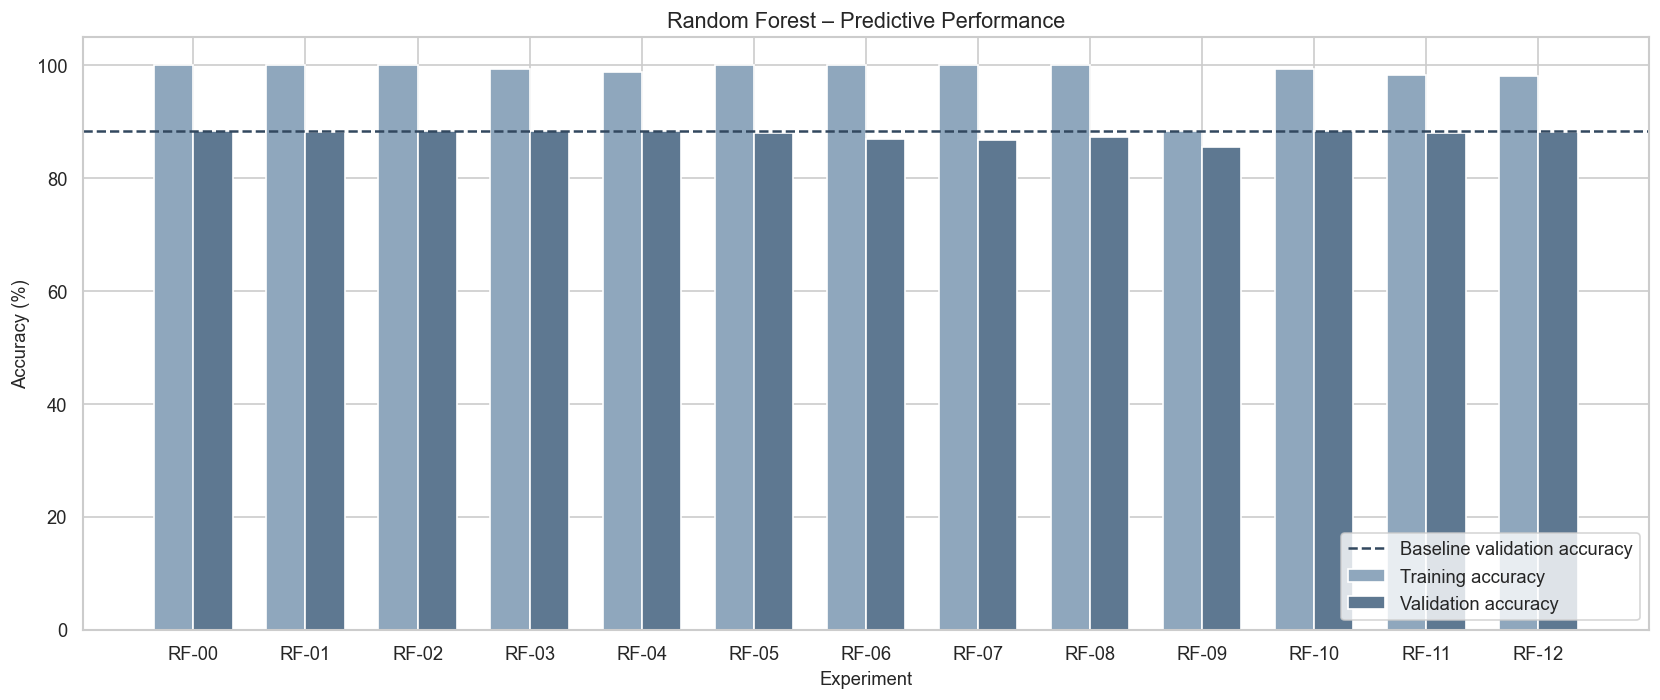

In [24]:
plot_df = experiments_df.sort_values("run_id")

fig, ax = plt.subplots(figsize=(14, 6))

positions = np.arange(len(plot_df))
width = 0.35

ax.bar(
    positions - width / 2,
    plot_df["train_accuracy"] * 100,
    width,
    label="Training accuracy",
    color=ACCENT_COLOR,
)

ax.bar(
    positions + width / 2,
    plot_df["val_accuracy"] * 100,
    width,
    label="Validation accuracy",
    color=PRIMARY_COLOR,
)

ax.axhline(
    baseline_result["val_accuracy"] * 100,
    color=SECONDARY_COLOR,
    linestyle="--",
    label="Baseline validation accuracy",
)

ax.set_xticks(positions)
ax.set_xticklabels(plot_df["run_id"])
ax.set_ylabel("Accuracy (%)")
ax.set_xlabel("Experiment")
ax.set_title("Random Forest – Predictive Performance")
ax.set_ylim(0, 105)
ax.legend(loc="lower right")

fig.tight_layout()

fig.savefig(
    FIGURES_DIR / "experiment_accuracy_comparison.png",
    bbox_inches="tight",
)

plt.show()

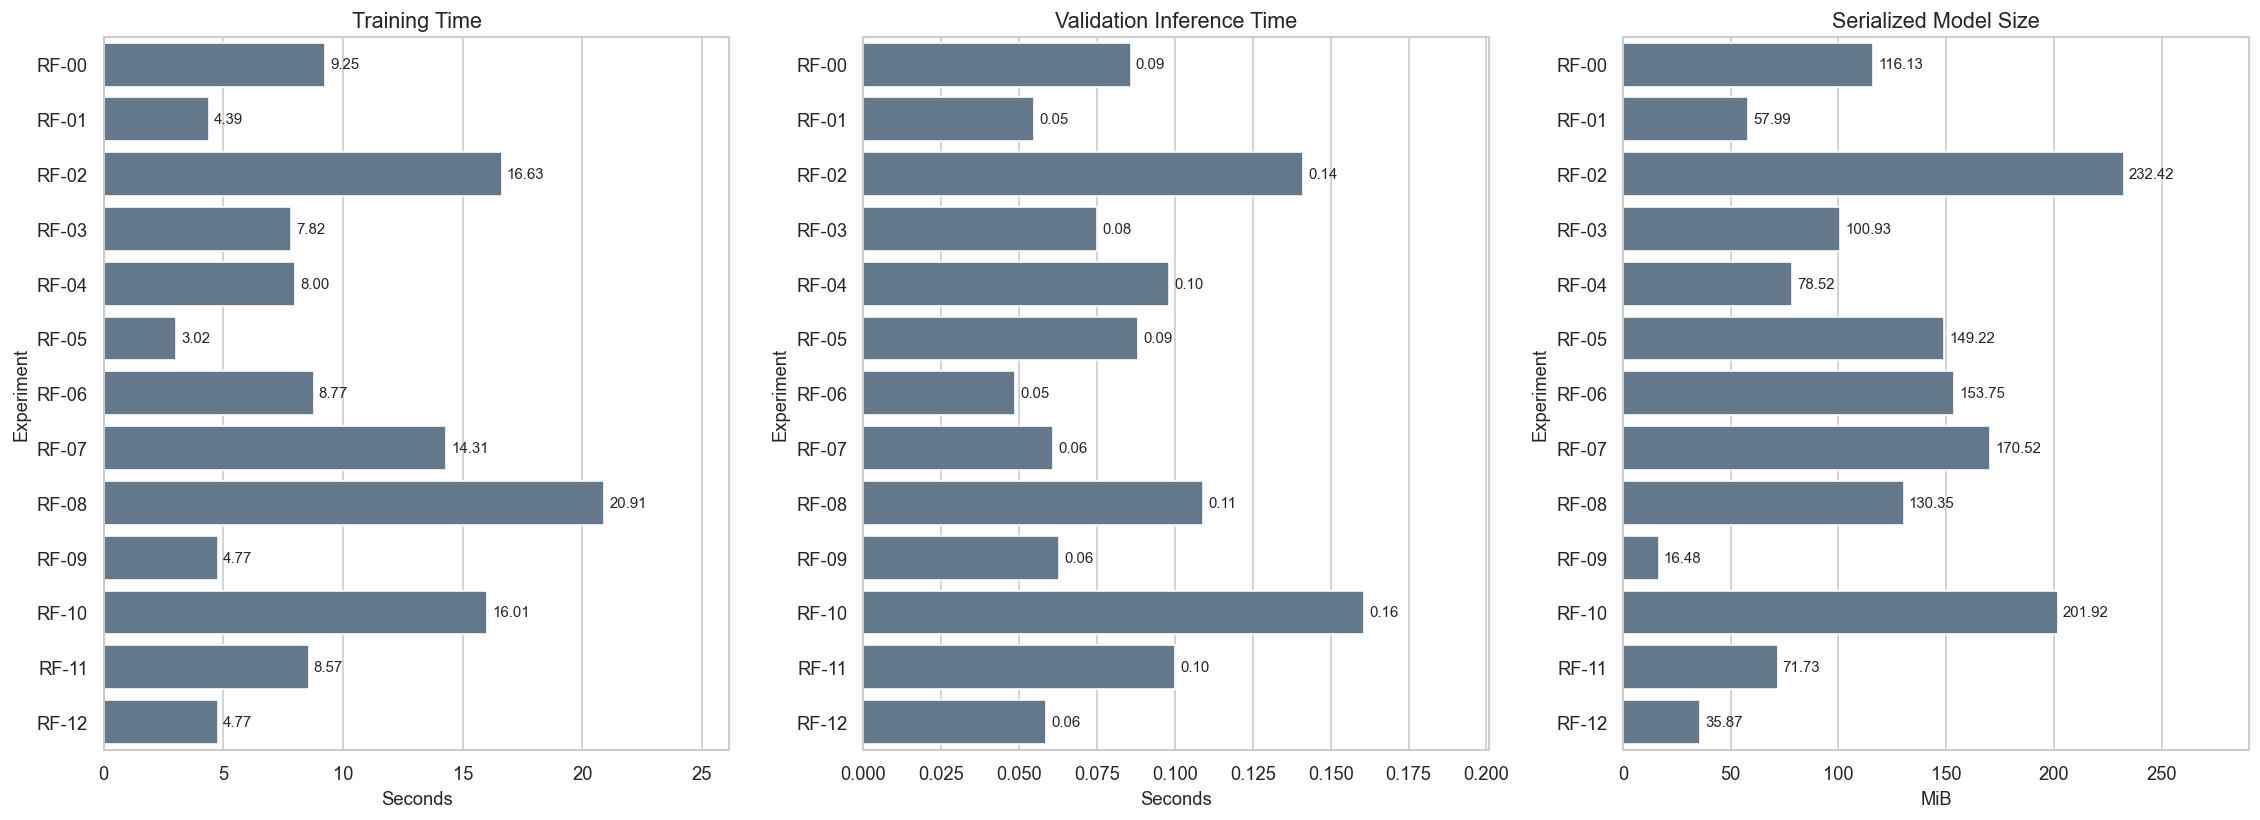

In [25]:
fig, axes = plt.subplots(1, 3, figsize=(19, 7))

metrics = [
    ("training_time_s", "Training Time", "Seconds"),
    ("inference_time_s", "Validation Inference Time", "Seconds"),
    ("model_size_mib", "Serialized Model Size", "MiB"),
]

for ax, (metric, title, xlabel) in zip(axes, metrics):
    sns.barplot(
        data=plot_df,
        y="run_id",
        x=metric,
        color=PRIMARY_COLOR,
        ax=ax,
    )

    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Experiment")

    ax.bar_label(
        ax.containers[0],
        fmt="%.2f",
        padding=3,
        fontsize=9,
    )

    ax.set_xlim(0, plot_df[metric].max() * 1.25)

fig.tight_layout()

fig.savefig(
    FIGURES_DIR / "experiment_efficiency_comparison.png",
    bbox_inches="tight",
)

plt.show()

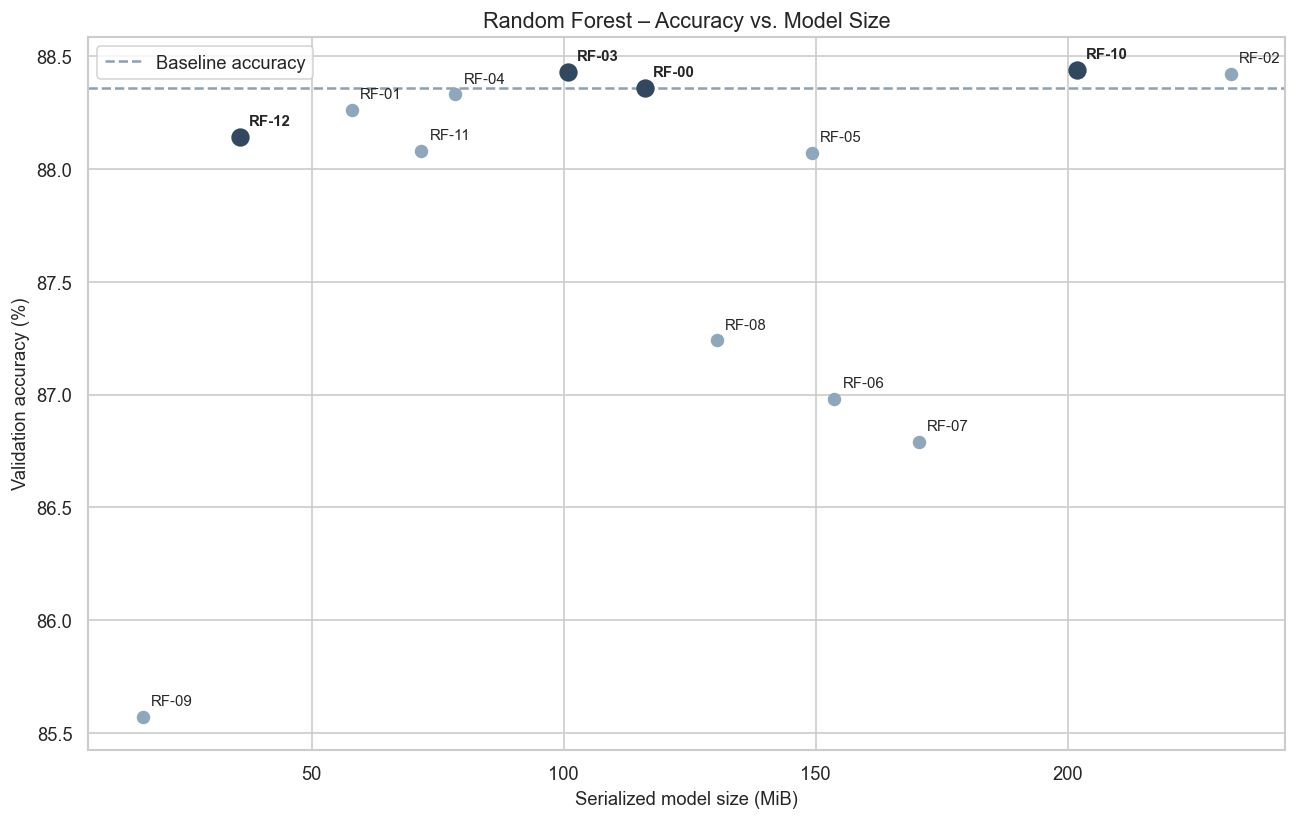

In [26]:
fig, ax = plt.subplots(figsize=(11, 7))

highlighted_runs = [
    "RF-00",
    "RF-03",
    "RF-10",
    "RF-12",
]

for _, row in plot_df.iterrows():
    highlighted = row["run_id"] in highlighted_runs

    ax.scatter(
        row["model_size_mib"],
        row["val_accuracy"] * 100,
        s=100 if highlighted else 50,
        color=SECONDARY_COLOR if highlighted else ACCENT_COLOR,
        zorder=3,
    )

    ax.annotate(
        row["run_id"],
        (
            row["model_size_mib"],
            row["val_accuracy"] * 100,
        ),
        xytext=(5, 7),
        textcoords="offset points",
        fontsize=9,
        fontweight="bold" if highlighted else "normal",
    )

ax.axhline(
    baseline_result["val_accuracy"] * 100,
    color=PRIMARY_COLOR,
    linestyle="--",
    alpha=0.7,
    label="Baseline accuracy",
)

ax.set_title("Random Forest – Accuracy vs. Model Size")
ax.set_xlabel("Serialized model size (MiB)")
ax.set_ylabel("Validation accuracy (%)")
ax.legend()

fig.tight_layout()

fig.savefig(
    FIGURES_DIR / "accuracy_model_size_tradeoff.png",
    bbox_inches="tight",
)

plt.show()

## 8. Final Model Selection and Evaluation

The final Random Forest configuration is selected
exclusively based on validation accuracy, with macro
F1-score and model size used as tie-breaking criteria.

The selected configuration is retrained using the
original shared training subset and evaluated on
the official test dataset.

No further hyperparameter optimization is performed
based on test results.

In [27]:
ranked_experiments = experiments_df.sort_values(
    ["val_accuracy", "val_macro_f1", "model_size_mib"],
    ascending=[False, False, True],
)

best_experiment = ranked_experiments.iloc[0]

best_model_params = json.loads(best_experiment["model_params"])

best_preprocessing_params = json.loads(best_experiment["preprocessing_params"])

print("Selected experiment:", best_experiment["run_id"])
print("Description:", best_experiment["description"])
print("Validation accuracy:", best_experiment["val_accuracy"])

display(
    pd.DataFrame(
        best_model_params.items(),
        columns=["Parameter", "Value"],
    )
)

Selected experiment: RF-10
Description: Performance-oriented
Validation accuracy: 0.8844


,Parameter,Value
0,bootstrap,True
1,ccp_alpha,0.0
2,class_weight,None
3,criterion,gini
4,max_depth,20
5,max_features,sqrt
6,max_leaf_nodes,None
7,max_samples,None
8,min_impurity_decrease,0.0
9,min_samples_leaf,1


In [28]:
final_model = build_random_forest(**best_model_params)

# Reuse the baseline representation selected by validation.
assert best_preprocessing_params == BASELINE_PREPROCESSING

start = perf_counter()

final_model.fit(X_train, y_train)

final_training_time = perf_counter() - start

final_val_pred = final_model.predict(X_val)

final_val_accuracy = accuracy_score(
    y_val,
    final_val_pred,
)

print(f"Final training time: {final_training_time:.2f} seconds")
print(f"Validation accuracy: {final_val_accuracy:.4f}")

assert np.isclose(
    final_val_accuracy,
    best_experiment["val_accuracy"],
)

Final training time: 21.72 seconds
Validation accuracy: 0.8844


### 8.1. Final Test Set Evaluation

The selected Random Forest model is evaluated on the
official Fashion-MNIST test dataset containing
10,000 previously unseen images.

The evaluation includes accuracy, macro F1-score,
class-level performance, confusion matrix and
inference time.

The test results are used exclusively for final
performance assessment, not for further optimization.

In [29]:
# Inference warm-up
final_model.predict(X_test)

# Repeated inference measurements
test_inference_times = []

for _ in range(5):
    start = perf_counter()

    y_test_pred = final_model.predict(X_test)

    test_inference_times.append(perf_counter() - start)

test_inference_time = float(np.median(test_inference_times))

test_accuracy = accuracy_score(
    y_test,
    y_test_pred,
)

test_macro_f1 = f1_score(
    y_test,
    y_test_pred,
    average="macro",
)

final_val_macro_f1 = f1_score(
    y_val,
    final_val_pred,
    average="macro",
)

final_results = pd.DataFrame(
    {
        "Metric": ["Accuracy", "Macro F1-score"],
        "Validation": [
            final_val_accuracy,
            final_val_macro_f1,
        ],
        "Test": [
            test_accuracy,
            test_macro_f1,
        ],
    }
)

display(final_results.round(4))

print(f"Final training time: {final_training_time:.4f}s")
print(f"Test inference time: {test_inference_time:.4f}s")

,Metric,Validation,Test
0,Accuracy,0.8844,0.8727
1,Macro F1-score,0.8832,0.8712


Final training time: 21.7181s
Test inference time: 0.1658s


In [30]:
final_class_report = pd.DataFrame(
    classification_report(
        y_test,
        y_test_pred,
        labels=np.arange(len(class_names)),
        target_names=class_names,
        output_dict=True,
        zero_division=0,
    )
).T

display(final_class_report.round(4))

final_class_report.to_csv(EXPERIMENTS_DIR / "random_forest_classification_report.csv")

,precision,recall,f1-score,support
T-shirt/top,0.8171,0.8580,0.8371,1000.0000
Trouser,0.9917,0.9560,0.9735,1000.0000
Pullover,0.7610,0.7930,0.7767,1000.0000
Dress,0.8728,0.9060,0.8891,1000.0000
Coat,0.7532,0.8120,0.7815,1000.0000
Sandal,0.9785,0.9550,0.9666,1000.0000
Shirt,0.7116,0.5750,0.6361,1000.0000
Sneaker,0.9279,0.9520,0.9398,1000.0000
Bag,0.9548,0.9710,0.9628,1000.0000
Ankle boot,0.9481,0.9490,0.9485,1000.0000


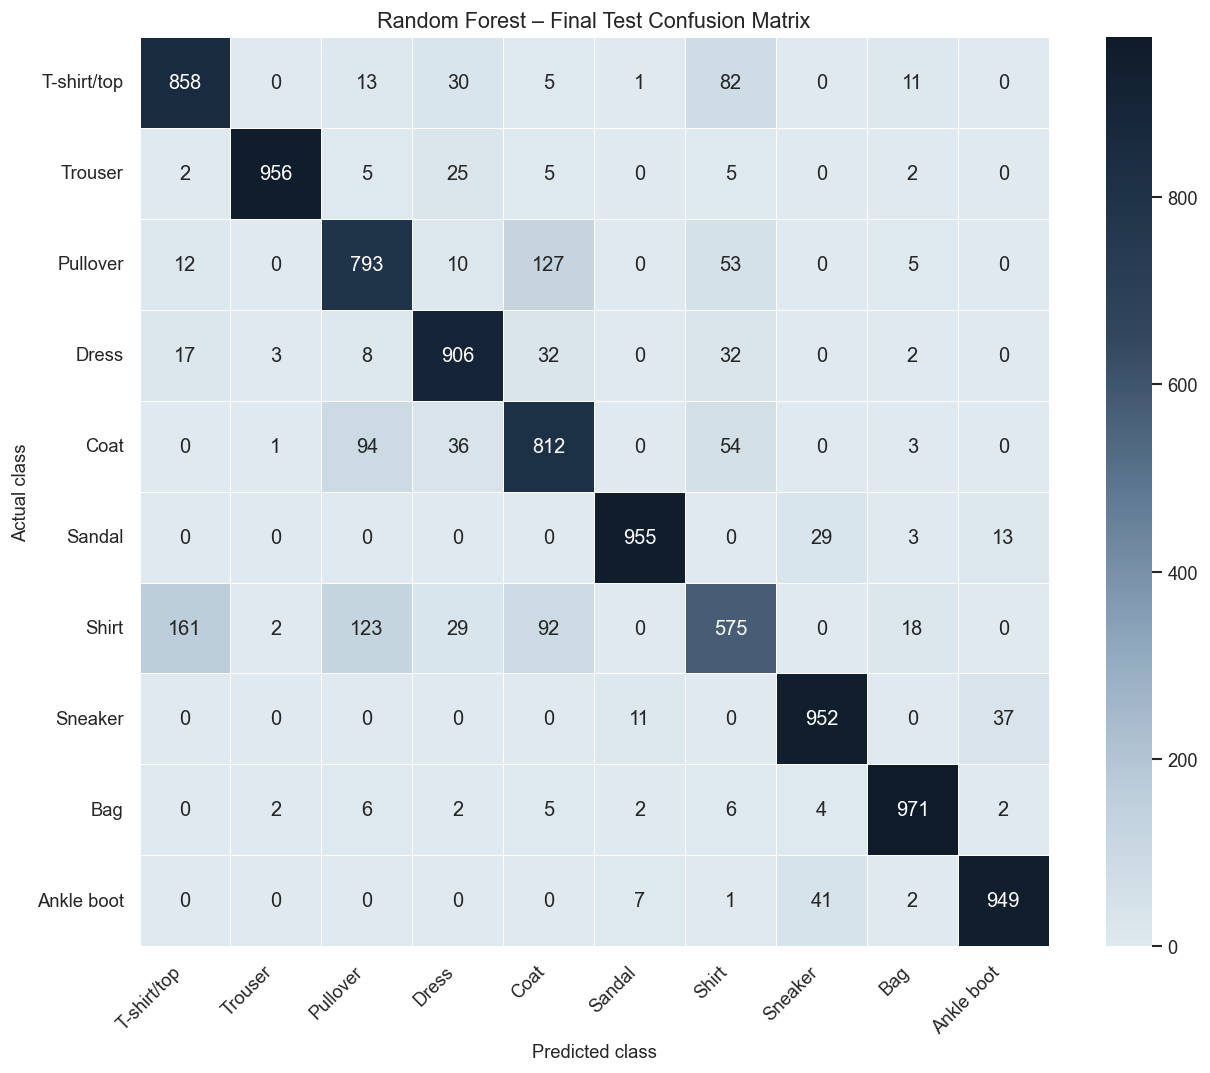

In [31]:
final_cm = confusion_matrix(
    y_test,
    y_test_pred,
    labels=np.arange(len(class_names)),
)

fig, ax = plt.subplots(figsize=(11, 9))

sns.heatmap(
    final_cm,
    annot=True,
    fmt="d",
    cmap=project_cmap,
    xticklabels=class_names,
    yticklabels=class_names,
    square=True,
    linewidths=0.5,
    ax=ax,
)

ax.set_title("Random Forest – Final Test Confusion Matrix")
ax.set_xlabel("Predicted class")
ax.set_ylabel("Actual class")

plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

fig.tight_layout()

fig.savefig(
    FIGURES_DIR / "final_confusion_matrix.png",
    bbox_inches="tight",
)

plt.show()

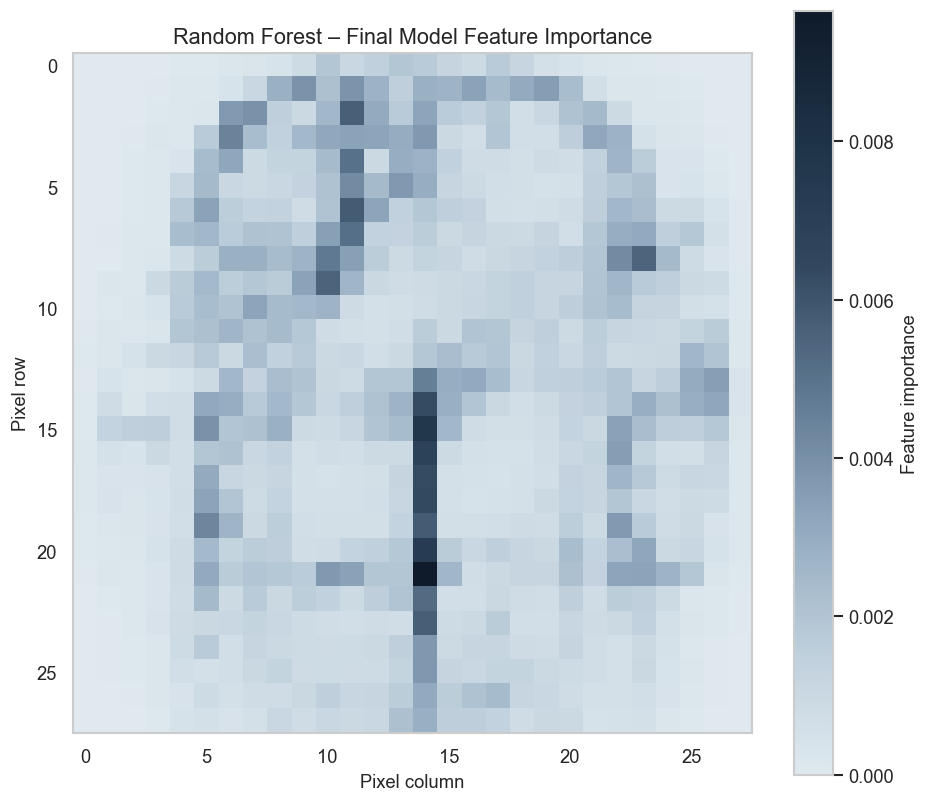

In [32]:
final_pixel_importance = final_model.feature_importances_.reshape(28, 28)

fig, ax = plt.subplots(figsize=(8, 7))

image = ax.imshow(
    final_pixel_importance,
    cmap=project_cmap,
    interpolation="nearest",
)

ax.set_title("Random Forest – Final Model Feature Importance")
ax.set_xlabel("Pixel column")
ax.set_ylabel("Pixel row")
ax.grid(False)

fig.colorbar(
    image,
    ax=ax,
    label="Feature importance",
)

fig.tight_layout()

fig.savefig(
    FIGURES_DIR / "final_feature_importance.png",
    bbox_inches="tight",
)

plt.show()

## 9. Model Persistence and Result Export

The final trained model and fitted preprocessing
pipeline are saved for reproducibility and future
inference.

The serialized model size is measured using
uncompressed model storage.

Experiment results and evaluation metrics are
exported as CSV files for subsequent comparison
with the other machine learning and deep learning
models.

In [33]:
model_path = ARTIFACTS_DIR / "random_forest.joblib"

preprocessor_path = ARTIFACTS_DIR / "random_forest_preprocessor.joblib"

joblib.dump(
    final_model,
    model_path,
    compress=0,
)

joblib.dump(
    preprocessor,
    preprocessor_path,
    compress=0,
)

final_model_size_mib = model_path.stat().st_size / 1024**2

preprocessor_size_mib = preprocessor_path.stat().st_size / 1024**2

print(f"Model saved to: {model_path}")
print(f"Model size: {final_model_size_mib:.2f} MiB")
print(f"Preprocessor size: {preprocessor_size_mib:.4f} MiB")

Model saved to: c:\Users\SUB\OneDrive - Horváth & Partner GmbH\Asztal\Github\DLProject_FashionMNIST\artifacts\ml\random_forest.joblib
Model size: 201.92 MiB
Preprocessor size: 0.0005 MiB


In [34]:
loaded_model = joblib.load(model_path)

loaded_predictions = loaded_model.predict(X_val[:100])

assert np.array_equal(
    loaded_predictions,
    final_val_pred[:100],
)

del loaded_model

print("Model persistence verification passed.")

Model persistence verification passed.


In [35]:
final_model_summary = pd.DataFrame(
    [
        {
            "model": "Random Forest",
            "selected_run": best_experiment["run_id"],
            "random_seed": RANDOM_SEED,
            "n_features": X_train.shape[1],
            "training_samples": len(y_train),
            "validation_samples": len(y_val),
            "test_samples": len(y_test),
            "train_accuracy": best_experiment["train_accuracy"],
            "train_macro_f1": best_experiment["train_macro_f1"],
            "val_accuracy": final_val_accuracy,
            "val_macro_f1": final_val_macro_f1,
            "test_accuracy": test_accuracy,
            "test_macro_f1": test_macro_f1,
            "preprocessing_time_s": baseline_preprocessing_time,
            "training_time_s": final_training_time,
            "test_inference_time_s": test_inference_time,
            "model_size_mib": final_model_size_mib,
            "preprocessor_size_mib": preprocessor_size_mib,
            "model_params": json.dumps(
                best_model_params,
                sort_keys=True,
            ),
            "preprocessing_params": json.dumps(
                best_preprocessing_params,
                sort_keys=True,
            ),
        }
    ]
)

final_model_summary.to_csv(
    EXPERIMENTS_DIR / "random_forest_final_metrics.csv",
    index=False,
)

display(final_model_summary.T)

,0
model,Random Forest
selected_run,RF-10
random_seed,42
n_features,784
training_samples,50000
validation_samples,10000
test_samples,10000
train_accuracy,0.99422
train_macro_f1,0.994219
val_accuracy,0.8844


## 10. Conclusions and Key Findings

### Predictive Performance

The final Random Forest model achieved a test accuracy
of 87.27% and a macro F1-score of 87.12%.

Hyperparameter optimization improved validation accuracy
from 88.36% to 88.44%, indicating that the baseline
configuration was already competitive.

### Model Complexity and Computational Efficiency

Increasing ensemble complexity produced only marginal
improvements in predictive performance.

The efficiency-oriented RF-12 configuration reduced
model size by 69.1% compared to the baseline, while
validation accuracy decreased by only 0.22 percentage
points.

These results highlight the importance of considering
computational requirements alongside predictive
performance.

### Alternative Feature Representations

Neither PCA nor HOG improved validation performance
under the evaluated configurations.

The original scaled pixel representation provided
the most favorable predictive performance.

Dimensionality reduction did not necessarily result
in smaller serialized models.

### Class-Level Performance

Shirt, Pullover and Coat remain the most challenging
clothing categories.

Four visually similar upper-body clothing category
pairs account for 61.7% of all test misclassifications.

This observation is consistent with the inter-class
cosine similarity analysis performed during EDA.

### Model Interpretability

Pixel-level feature importance provides insights into
the global feature utilization of the Random Forest.

However, impurity-based importance does not provide
causal or individual prediction explanations.

### Overall Conclusion

Random Forest provides a competitive traditional
machine learning reference for the subsequent
comparison with deep learning architectures.

The results motivate investigating whether convolutional
neural networks can improve classification performance
by explicitly learning spatial image features.

The findings are limited to the evaluated configurations,
dataset split and random seed.